# GTF Exon skipping tool
**Obiettivo:** Rilevare gli eventi di *exon skipping* nell'annotazione genica del cromosoma 10 (UCSC, formato `GTF`).

Un evento di *exon skipping* si verifica quando due esoni consecutivi E1 ed E2 del trascritto condividono rispettivamente il sito di splicing al 5' con un esone E1' e il sito al 3' con un esone E2' del riferimento, e E1' ed E2' non sono consecutivi:
- **CE** (*cassette exon*): un solo esone saltato
- **ME** (*multiple-exon skipping*): più esoni saltati

**Nota:** Per ogni gene, il trascritto con più esoni è il *trascritto di riferimento*

**Input:** Il dataset `GTF` del cromosoma 10 e il file `gene-transcript-map.txt`, necessario per mappare l’identificatore di un trascritto al corrispondente gene

**Output:** Un record per evento: `(id del trascritto, id del trascritto di riferimento, tipo [, numero di esoni se ME])`.

## 1) Parametri in input e importazione delle librerie

In [1]:
filename = "chr10.gtf"

In [2]:
filename_map = "gene-transcript-map.txt"

In [3]:
import re
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np

## 2) Creazione di un generatore di *esoni* da un file `GTF`
**INPUT**:
- nome del file `GTF`

**OUTPUT**:
- record `GTF` corrispondente ad un *esone*

In [4]:
def read_gtf_exons(gtf_filename):
    with open(gtf_filename) as f:
        for line in f:
            if line.startswith('#'):
                continue
            if line.split('\t')[2] == 'exon':
                yield line.strip()

## 3) Funzione di parsing dei dati dell'esone
**INPUT**:
- record `GTF` corrispondente ad un *esone*

**OUTPUT**:
- tupla `(transcript_id, start, end, strand)` che caratterizza l'*esone*

In [5]:
def parse_exon(exon_record):
    _, _, _, start, end, _, strand, _, attrs = exon_record.split('\t')
    transcript_id = re.search(r'\btranscript_id\s+"(.+?)"', attrs).group(1)
    return (transcript_id, int(start), int(end), strand)

## 4) Ottenimento della lista di esoni

In [6]:
exons_list = [parse_exon(exon_record) for exon_record in read_gtf_exons(filename)]

In [7]:
exons_list

[('ENST00000729394.1', 10781, 11242, '+'),
 ('ENST00000729394.1', 12261, 12409, '+'),
 ('ENST00000729394.1', 12798, 13109, '+'),
 ('ENST00000729392.1', 10784, 11242, '+'),
 ('ENST00000729392.1', 12798, 13000, '+'),
 ('ENST00000729392.1', 15263, 15997, '+'),
 ('ENST00000729389.1', 10848, 11242, '+'),
 ('ENST00000729389.1', 12798, 13000, '+'),
 ('ENST00000729389.1', 15263, 15403, '+'),
 ('ENST00000729389.1', 42753, 42846, '+'),
 ('ENST00000729389.1', 43266, 43395, '+'),
 ('ENST00000729389.1', 43628, 43869, '+'),
 ('ENST00000729390.1', 10849, 11242, '+'),
 ('ENST00000729390.1', 12798, 13000, '+'),
 ('ENST00000729390.1', 15263, 15403, '+'),
 ('ENST00000729390.1', 42753, 42846, '+'),
 ('ENST00000729390.1', 43211, 43395, '+'),
 ('ENST00000729390.1', 43628, 43867, '+'),
 ('ENST00000729391.1', 10854, 11242, '+'),
 ('ENST00000729391.1', 12798, 13000, '+'),
 ('ENST00000729391.1', 42748, 42846, '+'),
 ('ENST00000729391.1', 43266, 43395, '+'),
 ('ENST00000729391.1', 43628, 43867, '+'),
 ('ENST0000

## 5) Creazione dei dizionari degli esoni/strand per trascritto
- Il dizionario `exons_per_transcript` associa a ogni trascritto la lista delle coordinate di tutti i suoi `esoni`
- Il dizionario `strand_per_transcript` associa a ogni trascritto lo `strand` di appartenenza

Gli esoni vengono riordinati rispetto allo strand di appartenenza

In [8]:
exons_per_transcript = {}
strand_per_transcript = {}

for transcript_id, start, end, strand in exons_list:
    exons_per_transcript.setdefault(transcript_id, []).append((start, end))
    strand_per_transcript.setdefault(transcript_id, strand)

for transcript, exons in exons_per_transcript.items():
    exons.sort(reverse=(strand_per_transcript[transcript] == '-'), key=lambda x: x[0])

In [9]:
exons_per_transcript

{'ENST00000729394.1': [(10781, 11242), (12261, 12409), (12798, 13109)],
 'ENST00000729392.1': [(10784, 11242), (12798, 13000), (15263, 15997)],
 'ENST00000729389.1': [(10848, 11242),
  (12798, 13000),
  (15263, 15403),
  (42753, 42846),
  (43266, 43395),
  (43628, 43869)],
 'ENST00000729390.1': [(10849, 11242),
  (12798, 13000),
  (15263, 15403),
  (42753, 42846),
  (43211, 43395),
  (43628, 43867)],
 'ENST00000729391.1': [(10854, 11242),
  (12798, 13000),
  (42748, 42846),
  (43266, 43395),
  (43628, 43867)],
 'ENST00000729393.1': [(11458, 12029), (12798, 13000), (15263, 15993)],
 'ENST00000566940.3': [(20786, 20954), (16502, 16544), (13839, 14299)],
 'ENST00000729478.1': [(20786, 20931), (13851, 14299)],
 'ENST00000729479.1': [(20786, 20921), (13877, 16544)],
 'ENST00000729480.1': [(20786, 20922),
  (16502, 16544),
  (14497, 14603),
  (13884, 14299)],
 'ENST00000683798.2': [(20690, 20919), (16502, 16544), (14005, 14299)],
 'ENST00000562162.2': [(16502, 16549), (14497, 14659), (14061,

## 6) Creazione del dizionario dei trascritti per gene e scelta del trascritto di riferimento
Il dizionario `gene_transcripts_dict` associa a ogni gene un dizionario nidificato contenente l'*ID del trascritto di riferimento*, il set degli *ID di tutti i trascritti* associati a quel gene e lo *strand* di appartenenza.

Utilizzo `transcript_lookup` per mappare i transcript ID senza versione ai transcript ID con versione, per consistenza con il file  `gene-transcript-map.txt`

In [10]:
transcript_lookup = {}
for transcript_id in exons_per_transcript:
    transcript_lookup[transcript_id.split('.')[0]] = transcript_id

In [11]:
gene_transcripts_dict = {}

with open(filename_map) as f:
    next(f, None)
    for line in f:
        gene_id, transcript_id = line.strip().split()
        transcript_id = transcript_lookup.get(transcript_id)
        if transcript_id is not None:
            gene_transcripts_dict.setdefault(gene_id, {'ref': None, 'transcripts': set(), 'strand': None})['transcripts'].add(transcript_id)

In [12]:
for gene, gene_dict in gene_transcripts_dict.items():
    transcripts = gene_dict['transcripts']
    if transcripts:
        gene_dict['ref'] = max(transcripts, key=lambda t: len(exons_per_transcript[t]))
        gene_dict['strand'] = strand_per_transcript[gene_dict['ref']]

In [13]:
gene_transcripts_dict

{'ENSG00000231743': {'ref': 'ENST00000419388.1',
  'transcripts': {'ENST00000419388.1'},
  'strand': '+'},
 'ENSG00000226694': {'ref': 'ENST00000435539.1',
  'transcripts': {'ENST00000435539.1'},
  'strand': '+'},
 'ENSG00000287653': {'ref': 'ENST00000653889.1',
  'transcripts': {'ENST00000653889.1'},
  'strand': '+'},
 'ENSG00000237500': {'ref': 'ENST00000431209.1',
  'transcripts': {'ENST00000431209.1'},
  'strand': '+'},
 'ENSG00000233052': {'ref': 'ENST00000432987.1',
  'transcripts': {'ENST00000432987.1'},
  'strand': '-'},
 'ENSG00000227912': {'ref': 'ENST00000658923.1',
  'transcripts': {'ENST00000421077.1', 'ENST00000658923.1'},
  'strand': '+'},
 'ENSG00000271251': {'ref': 'ENST00000603398.1',
  'transcripts': {'ENST00000603398.1'},
  'strand': '+'},
 'ENSG00000185736': {'ref': 'ENST00000381312.6',
  'transcripts': {'ENST00000381305.1',
   'ENST00000381310.7',
   'ENST00000381312.6',
   'ENST00000469464.1',
   'ENST00000474762.5',
   'ENST00000477140.1',
   'ENST00000490172.1'

## 7) Definizione della funzione per il rilevamento di eventi di *exon skipping*
**INPUT**:
- *ID del trascritto di riferimento*
- *ID del trascritto alternativo*
- *strand* di appartenenza dei trascritti
- lista degli *esoni del trascritto di riferimento* (**ordinata**)
- lista degli *esoni del trascritto alternativo* (**ordinata**)


**OUTPUT**:
- lista di tuple `(id_tr, id_ref, event_type[, count])` corrispondenti a eventi di *exon skipping*

In [14]:
# d: indice della coordinata che identifica il sito di splicing al 5' dell'esone
# a: indice della coordinata che identifica il sito di splicing al 3' dell'esone
# s: direzione dovuta allo strand
# sr: indice da cui riprende la scansione del riferimento, aggiornato a ogni coppia
# head: l'indice dell'esone E1' nel trascritto di riferimento che condivide il sito di splicing al 5' con l'esone E1 del trascritto analizzato
def exon_skipping_finder(id_tr, id_ref, strand, ref, tr):
    d, a, s = (1, 0, 1) if strand == '+' else (0, 1, -1) 
    events = []
    sr = 0
    for e1, e2 in zip(tr, tr[1:]):
        head = None 
        for i, eR in enumerate(ref[sr:], start=sr):
            if head is None:
                if eR[d] == e1[d]:
                    head = i
                elif s * eR[d] > s * e1[d]:
                    sr = i
                    break
            elif eR[a] == e2[a]:
                count = i - head - 1
                if count > 0:
                    event_type = "ME" if count > 1 else "CE"
                    record = (id_tr, id_ref, event_type, count) if count > 1 else (id_tr, id_ref, event_type)
                    events.append(record)
                sr = i
                break
            elif s * eR[a] > s * e2[a]:
                sr = i - 1
                break 
        else:
            return events
    return events

## 8) Ricerca degli eventi di exon skipping relativi allo specifico dataset 


In [15]:
events = []
for gene, gene_dict in gene_transcripts_dict.items():
    reference = gene_dict['ref']
    strand = gene_dict['strand']
    for transcript in gene_dict['transcripts']:
        if transcript == reference:
            continue
        events_per_transcript = exon_skipping_finder(transcript,
                                      reference,
                                      strand,
                                      exons_per_transcript[reference],
                                      exons_per_transcript[transcript]
                                     )   
        events.extend(events_per_transcript)

In [16]:
print(*events, sep='\n')

('ENST00000376528.8', 'ENST00000409983.7', 'CE')
('ENST00000376528.8', 'ENST00000409983.7', 'ME', 2)
('ENST00000468003.5', 'ENST00000409983.7', 'CE')
('ENST00000484642.5', 'ENST00000409983.7', 'ME', 2)
('ENST00000447081.5', 'ENST00000409983.7', 'CE')
('ENST00000496741.5', 'ENST00000409983.7', 'CE')
('ENST00000496741.5', 'ENST00000409983.7', 'ME', 2)
('ENST00000377266.7', 'ENST00000454679.7', 'ME', 2)
('ENST00000377602.5', 'ENST00000648997.1', 'CE')
('ENST00000483339.2', 'ENST00000496261.6', 'CE')
('ENST00000373880.9', 'ENST00000486074.2', 'CE')
('ENST00000659541.1', 'ENST00000652859.1', 'CE')
('ENST00000371994.8', 'ENST00000371996.9', 'ME', 2)
('ENST00000464741.2', 'ENST00000327946.12', 'CE')
('ENST00000415731.2', 'ENST00000628416.1', 'ME', 2)
('ENST00000443748.6', 'ENST00000672817.1', 'CE')
('ENST00000443748.6', 'ENST00000672817.1', 'ME', 3)
('ENST00000660354.1', 'ENST00000666640.1', 'CE')
('ENST00000666262.1', 'ENST00000666640.1', 'CE')
('ENST00000434189.2', 'ENST00000666640.1', 'CE'

## 9) Interpretazione dei risultati
Possiamo notare che:
- Gli eventi di *exon skipping* più frequenti sono di tipo **CE** e la frequenza degli eventi diminuisce drasticamente all'aumentare del numero di esoni esclusi
    - Infatti, biologicamente è più raro saltare molti esoni consecutivi rispetto a saltarne uno solo
- Oltre la metà dei geni multi-isoforma presenta eventi di *exon skipping*
- La differenza tra media e mediana suggerisce una distribuzione asimmetrica, in cui pochi geni concentrano un numero elevato di eventi rispetto alla maggioranza

In [17]:
n_genes_multi = sum(len(gene_dict['transcripts']) > 1 for gene_dict in gene_transcripts_dict.values())
print(f"Numero di geni multi-isoforma: {n_genes_multi}")

types = Counter(e[2] for e in events)
print(f"Numero di eventi di exon skipping: {len(events)} -> " + ", ".join(f"{t}: {n} ({n/len(events):.0%})" for t, n in types.items()))

events_per_gene = Counter(e[1] for e in events)

counts = [events_per_gene.get(gene_dict['ref'], 0)
          for gene_dict in gene_transcripts_dict.values()
          if len(gene_dict['transcripts']) > 1]

n_genes_with_events = sum(c > 0 for c in counts)
print(f"Geni multi-isoforma con almeno 1 evento: {n_genes_with_events} ({n_genes_with_events/n_genes_multi:.0%})")
print(f"Numero medio di eventi per gene multi-isoforma: {np.mean(counts):.2f}")
print(f"Mediana eventi per gene multi-isoforma: {np.median(counts)}")

Numero di geni multi-isoforma: 1457
Numero di eventi di exon skipping: 4733 -> CE: 3410 (72%), ME: 1323 (28%)
Geni multi-isoforma con almeno 1 evento: 749 (51%)
Numero medio di eventi per gene multi-isoforma: 3.25
Mediana eventi per gene multi-isoforma: 1.0


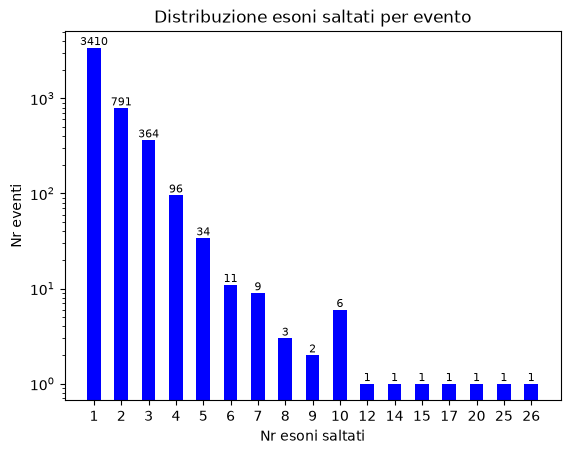

In [18]:
sizes = Counter(e[3] if len(e) == 4 else 1 for e in events) 
sorted_sizes = sorted(sizes.items())
x, y = [str(exons) for exons, events in sorted_sizes], [events for exons, events in sorted_sizes]      
bars = plt.bar(x, y, color='blue', width = 0.5)
plt.yscale('log')
plt.bar_label(bars, fontsize=8) 
plt.xlabel('Nr esoni saltati')
plt.ylabel('Nr eventi')
plt.title('Distribuzione esoni saltati per evento')
plt.show()